Import stability package

(from [https://github.com/nogueirs/JMLR2018](https://github.com/nogueirs/JMLR2018))

In [2]:
import sys
sys.path.append('../../')
from fseval.analysis.lib import stability
stability.getStability

<function fseval.analysis.lib.stability.getStability(Z)>

Load binary subsets data

In [3]:
import pandas as pd
from tqdm import tqdm
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
result_dirs = ['../../results/11714894_subsets', '../../results/11824789']
chunks = []
for _, dataset in tqdm(datacol.iterrows(), total=len(datacol)):
    for result_dir in result_dirs:
        respath = os.path.join(result_dir, 'binary_subsets', dataset.path + '.csv')
        if os.path.exists(respath):
            res = pd.read_csv(respath)
            # dataset_ = dataset.drop(labels=[ # `labels` cause `dataset` is Series
            #     'directory', 'path', 'adapter']) # drop some cols to save space
            # res = res.assign(**dataset_)
            chunks.append(res)
bindata = pd.concat(chunks)
del chunks
print('bindata successfully collected.')

100%|██████████| 1828/1828 [00:11<00:00, 164.56it/s]
bindata successfully collected.


In [4]:
# bindata.to_csv('bindata.csv', index=False)

Compute stabilities

In [5]:
import numpy as np
import time

def compute_stability(replicas):
    to_int = lambda array: list(map(int, array))
    Z = replicas.str.split(pat=',').map(to_int).values
    Z = np.array(Z.tolist()) # make numpy appreciate both dimensions properly.
    M, d = Z.shape
    if M == 1: # theres only 1 replica available. stability can't be computed.
        return { 'stability': np.nan, 'lower': np.nan, 'upper': np.nan }
    return stability.confidenceIntervals(Z)

def split_cols(row):
    return pd.Series({ 'stability': 
        [row.binary_subset['lower'],\
        row.binary_subset['stability'],\
        row.binary_subset['upper']]
    })

s = time.time()
stabdata_ = bindata\
    .groupby(['description', 'ranking_method', 'max_features'])\
    .agg({ 'binary_subset': compute_stability })\
    .apply(split_cols, axis=1)\
    .explode('stability')\
    .reset_index()
stabdata_['stability'] = pd.to_numeric(stabdata_['stability'])
print('took {:.5f} seconds'.format(time.time() - s))
print(stabdata_.dtypes)
stabdata_

took 25.07816 seconds
description        object
ranking_method     object
max_features        int64
stability         float64
dtype: object


,description,ranking_method,max_features,stability
0,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,1,0.352391
1,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,1,0.603356
2,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,1,0.854321
3,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,2,0.199489
4,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,2,0.345813
...,...,...,...,...
13132,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,9,0.082126
13133,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,9,0.125902
13134,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,10,0.028232
13135,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,10,0.086232


Merge more info into data rows

In [6]:
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
rebate = pd.read_csv('./data/rebate-datasets.csv')[['directory', 'heritability', 'edm']]
info = datacol.merge(rebate, on='directory')\
              .drop(columns=['replica_no', 'directory', 'path'])\
              .drop_duplicates(ignore_index=True)
info

,adapter,replicas,name,p,n,description,p_informative,heritability,edm
0,rebate,24,Continuous Features,20,1600,"Continuous Features [p=20,n=1600,p_=2,h=0.4,ed...","18,19","0,4",Easy
1,rebate,24,20_bit_mutliplexer,20,2000,"20_bit_mutliplexer [p=20,n=2000,p_=20,h=1]","0,1,2,3",1,None
2,rebate,24,Continuous Endpoints (Threshold),20,1600,"Continuous Endpoints (Threshold) [p=20,n=1600,...","18,19","0,4",Easy
3,rebate,24,9 Class Balanced Data (2-way Epistasis+ME),20,1600,9 Class Balanced Data (2-way Epistasis+ME) [p=...,"18,19",1,Easy
4,rebate,24,Total # of Features,1000,1600,"Total # of Features [p=1000,n=1600,p_=2,h=0.4,...","998,999","0,4",Easy
...,...,...,...,...,...,...,...,...,...
71,rebate,24,Missing Values,20,1600,"Missing Values [p=20,n=1600,p_=2,h=0.4,edm=Eas...","18,19","0,4",Easy
72,rebate,24,Missing Values,20,1600,"Missing Values [p=20,n=1600,p_=2,h=0.4,edm=Eas...","18,19","0,4",Easy
73,rebate,24,Missing Values,20,1600,"Missing Values [p=20,n=1600,p_=2,h=0.4,edm=Eas...","18,19","0,4",Easy
74,rebate,24,2 Additive Main Effects,20,1600,"2 Additive Main Effects [p=20,n=1600,p_=2,h=0....","18,19","0,4",Easy


In [7]:
stabdata = stabdata_.merge(info, on='description', how='left')
print(stabdata.dtypes)
stabdata

description        object
ranking_method     object
max_features        int64
stability         float64
adapter            object
replicas           object
name               object
p                  object
n                  object
p_informative      object
heritability       object
edm                object
dtype: object


,description,ranking_method,max_features,stability,adapter,replicas,name,p,n,p_informative,heritability,edm
0,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,1,0.352391,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy
1,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,1,0.603356,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy
2,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,1,0.854321,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy
3,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,2,0.199489,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy
4,"1 Main Effect [p=20,n=1600,p_=1,h=0.05,edm=Easy]",ExtraTrees,2,0.345813,rebate,24,1 Main Effect,20,1600,19,"0,05",Easy
...,...,...,...,...,...,...,...,...,...,...,...,...
13132,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,9,0.082126,rebate,24,XOR Models,20,1600,"15,16,17,18,19",1,None
13133,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,9,0.125902,rebate,24,XOR Models,20,1600,"15,16,17,18,19",1,None
13134,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,10,0.028232,rebate,24,XOR Models,20,1600,"15,16,17,18,19",1,None
13135,"XOR Models [p=20,n=1600,p_=5,h=1]",RFE w/XGBoost,10,0.086232,rebate,24,XOR Models,20,1600,"15,16,17,18,19",1,None


In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
# rectangular = pd.pivot_table(stabdata,\
#     values='stability',\
#     index=['description'],\
#     columns=['ranking_method'])
# f, ax = plt.subplots(figsize=(7, 25))
# plt.yticks(rotation=0)
# plt.xticks(rotation=0)
# g = sns.heatmap(rectangular,\
#     annot=True, fmt=".1f", linewidths=.5,\
#     cmap="YlGnBu", yticklabels=True, ax=ax)

In [9]:
# one_main_effect = stabdata[stabdata['description'].str.contains('1 Main Effect')]
# one_main_effect['h'] = one_main_effect['description'].str.extract(r',h=(.*),edm=')
# one_main_effect['edm'] = one_main_effect['description'].str.extract(r',edm=(.*)]')
# one_main_effect.head()

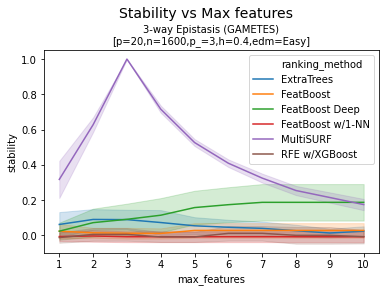

In [12]:
sns.lineplot(data=stabdata[stabdata['name'] == '3-way Epistasis (GAMETES)'],
    x='max_features', y='stability', #style='ranking_method',
    hue='ranking_method', #size='edm'
    # err_style=None,
    # markers=True
    )
plt.xticks(np.arange(1, 10+1, 1.0))
plt.suptitle('Stability vs Max features', size=14)
plt.subplots_adjust(top=.83)
plt.title("3-way Epistasis (GAMETES)\n[p=20,n=1600,p_=3,h=0.4,edm=Easy]", size=10)
plt.savefig('/Users/dunnkers/git/research-internship-report/img/3way_stab.svg')
plt.show()

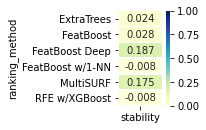

In [16]:
rectangular = pd.pivot_table(stabdata[stabdata['name'] == '3-way Epistasis (GAMETES)'],\
    values='stability',\
    index=['ranking_method'])
f, ax = plt.subplots(figsize=(1, 1.75))
plt.yticks(rotation=0)
plt.xticks(rotation=0)
g = sns.heatmap(rectangular,\
    annot=True, fmt=".3f", linewidths=.5,\
    cmap="YlGnBu", yticklabels=True, ax=ax,
    vmin=0, vmax=1)

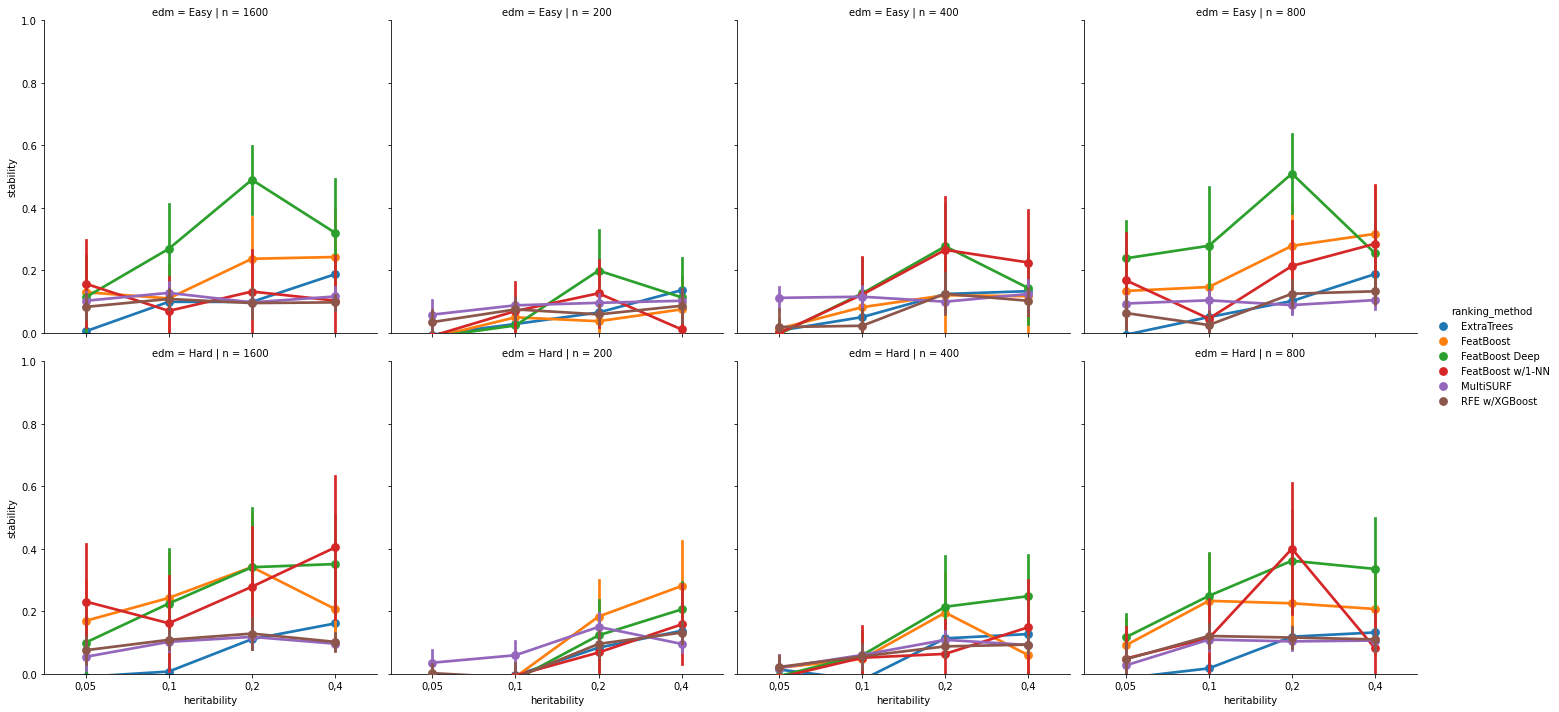

In [165]:
dat = stabdata[stabdata['name'] == '2-way Epistasis']
g = sns.catplot(data=dat, x='heritability', y='stability', col='n', hue='ranking_method', row='edm', kind='point')
g.set(ylim=(0, 1))